In [8]:
import pandas as pd
import numpy as np

df = pd.read_csv("osteoporosis_clean_dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (3545, 43)


In [9]:
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["Osteoporosis"].value_counts())

print("\nTarget percentage:")
print(df["Osteoporosis"].value_counts(normalize=True) * 100)

print("\nDuplicate participants:")
print(df["SEQN"].duplicated().sum())

print("\nMissing target values:")
print(df["Osteoporosis"].isna().sum())

Dataset shape: (3545, 43)

Target distribution:
Osteoporosis
0    3341
1     204
Name: count, dtype: int64

Target percentage:
Osteoporosis
0    94.245416
1     5.754584
Name: proportion, dtype: float64

Duplicate participants:
0

Missing target values:
0


In [10]:
# Original 28 predictors
feature_cols = [
    # Demographic
    "RIDAGEYR", "RIAGENDR", "RIDRETH3", "INDFMPIR",

    # Body measurements
    "BMXWT", "BMXHT", "BMXBMI", "BMXWAIST", "BMXHIP",

    # Physical activity
    "PAQ605", "PAQ620", "PAQ635", "PAQ650", "PAQ665", "PAD680",

    # Alcohol
    "Alcohol_Ever",

    # Nutrition
    "DR1TKCAL", "DR1TPROT", "DR1TVD",
    "DR1TCALC", "DR1TPHOS", "DR1TMAGN",

    # Medical history
    "MCQ080", "MCQ160A", "MCQ160M",
    "MCQ160L", "MCQ160P", "MCQ220"
]

# Create engineered-feature copy
engineered = df.copy()

# 1. Waist-to-height ratio
engineered["Waist_Height_Ratio"] = (
    engineered["BMXWAIST"] / engineered["BMXHT"]
)

# 2. Waist-to-hip ratio
engineered["Waist_Hip_Ratio"] = (
    engineered["BMXWAIST"] / engineered["BMXHIP"]
)

# 3. Age × BMI
engineered["Age_BMI"] = (
    engineered["RIDAGEYR"] * engineered["BMXBMI"]
)

# 4. Calcium per 1000 kcal
engineered["Calcium_per_1000kcal"] = (
    engineered["DR1TCALC"] / engineered["DR1TKCAL"] * 1000
)

# 5. Vitamin D per 1000 kcal
engineered["VitaminD_per_1000kcal"] = (
    engineered["DR1TVD"] / engineered["DR1TKCAL"] * 1000
)

# 6. Protein per kg body weight
engineered["Protein_per_kg"] = (
    engineered["DR1TPROT"] / engineered["BMXWT"]
)

# 7. Physical Activity Score
activity_cols = [
    "PAQ605",
    "PAQ620",
    "PAQ635",
    "PAQ650",
    "PAQ665"
]

engineered["Physical_Activity_Score"] = (
    engineered[activity_cols].sum(axis=1, min_count=1)
)

new_features = [
    "Waist_Height_Ratio",
    "Waist_Hip_Ratio",
    "Age_BMI",
    "Calcium_per_1000kcal",
    "VitaminD_per_1000kcal",
    "Protein_per_kg",
    "Physical_Activity_Score"
]

engineered_feature_cols = feature_cols + new_features

X = engineered[engineered_feature_cols].copy()
y = engineered["Osteoporosis"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nNew features created:")
print(new_features)

X shape: (3545, 35)
y shape: (3545,)

New features created:
['Waist_Height_Ratio', 'Waist_Hip_Ratio', 'Age_BMI', 'Calcium_per_1000kcal', 'VitaminD_per_1000kcal', 'Protein_per_kg', 'Physical_Activity_Score']


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training samples: (2836, 35)
Testing samples: (709, 35)

Training target:
Osteoporosis
0    2673
1     163
Name: count, dtype: int64

Testing target:
Osteoporosis
0    668
1     41
Name: count, dtype: int64


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Continuous numerical features
numeric_features = [
    "RIDAGEYR",
    "INDFMPIR",
    "BMXWT",
    "BMXHT",
    "BMXBMI",
    "BMXWAIST",
    "BMXHIP",
    "PAD680",
    "DR1TKCAL",
    "DR1TPROT",
    "DR1TVD",
    "DR1TCALC",
    "DR1TPHOS",
    "DR1TMAGN",

    # Engineered features
    "Waist_Height_Ratio",
    "Waist_Hip_Ratio",
    "Age_BMI",
    "Calcium_per_1000kcal",
    "VitaminD_per_1000kcal",
    "Protein_per_kg",
    "Physical_Activity_Score"
]

# Categorical features
categorical_features = [
    "RIAGENDR",
    "RIDRETH3"
]

# Binary features
binary_features = [
    "PAQ605",
    "PAQ620",
    "PAQ635",
    "PAQ650",
    "PAQ665",
    "Alcohol_Ever",
    "MCQ080",
    "MCQ160A",
    "MCQ160M",
    "MCQ160L",
    "MCQ160P",
    "MCQ220"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),

        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            categorical_features
        ),

        (
            "bin",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent"))
            ]),
            binary_features
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

# Same 5 folds for model comparison
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression pipeline
logistic_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Metrics
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy"
}

# 5-fold CV on TRAINING DATA ONLY
logistic_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("LOGISTIC REGRESSION - 5 FOLD CV")
print("--------------------------------")

for metric in scoring:
    values = logistic_cv["test_" + metric]

    print(
        f"{metric}: "
        f"{values.mean():.3f} "
        f"(+/- {values.std():.3f})"
    )

LOGISTIC REGRESSION - 5 FOLD CV
--------------------------------
roc_auc: 0.854 (+/- 0.031)
pr_auc: 0.351 (+/- 0.039)
recall: 0.755 (+/- 0.064)
precision: 0.188 (+/- 0.008)
f1: 0.301 (+/- 0.014)
balanced_accuracy: 0.778 (+/- 0.028)


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_cv = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("RANDOM FOREST - 5 FOLD CV")
print("--------------------------")

for metric in scoring:
    values = rf_cv["test_" + metric]

    print(
        f"{metric}: "
        f"{values.mean():.3f} "
        f"(+/- {values.std():.3f})"
    )

RANDOM FOREST - 5 FOLD CV
--------------------------
roc_auc: 0.848 (+/- 0.051)
pr_auc: 0.374 (+/- 0.081)
recall: 0.245 (+/- 0.096)
precision: 0.494 (+/- 0.147)
f1: 0.324 (+/- 0.117)
balanced_accuracy: 0.615 (+/- 0.048)


In [8]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Calculate imbalance ratio from TRAINING data
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Negative cases:", negative)
print("Positive cases:", positive)
print("scale_pos_weight:", scale_pos_weight)

xgb_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", XGBClassifier(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_cv = cross_validate(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("\nXGBOOST - 5 FOLD CV")
print("--------------------")

for metric in scoring:
    values = xgb_cv["test_" + metric]

    print(
        f"{metric}: "
        f"{values.mean():.3f} "
        f"(+/- {values.std():.3f})"
    )

Negative cases: 2673
Positive cases: 163
scale_pos_weight: 16.39877300613497

XGBOOST - 5 FOLD CV
--------------------
roc_auc: 0.846 (+/- 0.033)
pr_auc: 0.349 (+/- 0.075)
recall: 0.510 (+/- 0.066)
precision: 0.267 (+/- 0.032)
f1: 0.350 (+/- 0.039)
balanced_accuracy: 0.712 (+/- 0.033)


In [9]:
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

lgbm_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", LGBMClassifier(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=31,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

lgbm_cv = cross_validate(
    lgbm_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("LIGHTGBM - 5 FOLD CV")
print("---------------------")

for metric in scoring:
    values = lgbm_cv["test_" + metric]

    print(
        f"{metric}: "
        f"{values.mean():.3f} "
        f"(+/- {values.std():.3f})"
    )

LIGHTGBM - 5 FOLD CV
---------------------
roc_auc: 0.836 (+/- 0.040)
pr_auc: 0.357 (+/- 0.069)
recall: 0.239 (+/- 0.084)
precision: 0.483 (+/- 0.105)
f1: 0.315 (+/- 0.088)
balanced_accuracy: 0.612 (+/- 0.042)


In [ ]:
import numpy as np
import torch

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score
)

from pytorch_tabnet.tab_model import TabNetClassifier

tabnet_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tabnet_results = {
    "roc_auc": [],
    "pr_auc": [],
    "recall": [],
    "precision": [],
    "f1": [],
    "balanced_accuracy": []
}

for fold, (train_idx, val_idx) in enumerate(
    tabnet_cv.split(X_train, y_train),
    start=1
):

    print(f"\n========== FOLD {fold} ==========")

    # -----------------------------
    # Split current fold
    # -----------------------------
    X_fold_train_raw = X_train.iloc[train_idx]
    X_fold_val_raw = X_train.iloc[val_idx]

    y_fold_train = (
        y_train.iloc[train_idx]
        .to_numpy()
        .astype(np.int64)
    )

    y_fold_val = (
        y_train.iloc[val_idx]
        .to_numpy()
        .astype(np.int64)
    )

    # -----------------------------
    # Preprocessing INSIDE the fold
    # -----------------------------
    fold_preprocessor = clone(preprocessor)

    X_fold_train = fold_preprocessor.fit_transform(
        X_fold_train_raw
    )

    X_fold_val = fold_preprocessor.transform(
        X_fold_val_raw
    )

    X_fold_train = np.asarray(
        X_fold_train,
        dtype=np.float32
    )

    X_fold_val = np.asarray(
        X_fold_val,
        dtype=np.float32
    )

    # -----------------------------
    # Class imbalance
    # -----------------------------
    negative = np.sum(y_fold_train == 0)
    positive = np.sum(y_fold_train == 1)

    positive_weight = negative / positive

    # -----------------------------
    # TabNet
    # -----------------------------
    tabnet = TabNetClassifier(
        n_d=16,
        n_a=16,
        n_steps=5,
        gamma=1.5,
        lambda_sparse=1e-4,

        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(
            lr=2e-2
        ),

        mask_type="entmax",

        seed=42 + fold,
        verbose=0
    )

    tabnet.fit(
        X_fold_train,
        y_fold_train,

        eval_set=[
            (X_fold_val, y_fold_val)
        ],

        eval_name=["valid"],
        eval_metric=["auc"],

        max_epochs=200,
        patience=30,

        batch_size=256,
        virtual_batch_size=64,

        weights={
            0: 1.0,
            1: positive_weight
        }
    )

    # -----------------------------
    # Predictions
    # -----------------------------
    probabilities = tabnet.predict_proba(
        X_fold_val
    )[:, 1]

    predictions = (
        probabilities >= 0.50
    ).astype(int)

    # -----------------------------
    # Metrics
    # -----------------------------
    roc = roc_auc_score(
        y_fold_val,
        probabilities
    )

    pr = average_precision_score(
        y_fold_val,
        probabilities
    )

    recall = recall_score(
        y_fold_val,
        predictions
    )

    precision = precision_score(
        y_fold_val,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_fold_val,
        predictions,
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_fold_val,
        predictions
    )

    # Store
    tabnet_results["roc_auc"].append(roc)
    tabnet_results["pr_auc"].append(pr)
    tabnet_results["recall"].append(recall)
    tabnet_results["precision"].append(precision)
    tabnet_results["f1"].append(f1)
    tabnet_results["balanced_accuracy"].append(
        balanced_acc
    )

    print(f"ROC-AUC: {roc:.3f}")
    print(f"PR-AUC: {pr:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"F1: {f1:.3f}")
    print(
        f"Balanced Accuracy: "
        f"{balanced_acc:.3f}"
    )


========== FOLD 1 ==========

Early stopping occurred at epoch 37 with best_epoch = 7 and best_valid_auc = 0.8601


C:\Users\prasa\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


ROC-AUC: 0.860
PR-AUC: 0.285
Recall: 0.727
Precision: 0.178
F1: 0.286
Balanced Accuracy: 0.760

========== FOLD 2 ==========

Early stopping occurred at epoch 67 with best_epoch = 37 and best_valid_auc = 0.88248


C:\Users\prasa\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


ROC-AUC: 0.882
PR-AUC: 0.326
Recall: 0.818
Precision: 0.190
F1: 0.309
Balanced Accuracy: 0.801

========== FOLD 3 ==========

Early stopping occurred at epoch 42 with best_epoch = 12 and best_valid_auc = 0.88912


C:\Users\prasa\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


ROC-AUC: 0.889
PR-AUC: 0.486
Recall: 0.909
Precision: 0.161
F1: 0.274
Balanced Accuracy: 0.808

========== FOLD 4 ==========


In [ ]:
print("\nTABNET - 5 FOLD CV")
print("--------------------")

for metric, values in tabnet_results.items():
    values = np.array(values)

    print(
        f"{metric}: "
        f"{values.mean():.3f} "
        f"(+/- {values.std():.3f})"
    )

In [ ]:
tabnet_configs = [
    {
        "name": "Baseline",
        "n_d": 16,
        "n_a": 16,
        "n_steps": 5,
        "gamma": 1.5,
        "lr": 0.02
    },

    {
        "name": "Config_1",
        "n_d": 8,
        "n_a": 8,
        "n_steps": 3,
        "gamma": 1.3,
        "lr": 0.02
    },

    {
        "name": "Config_2",
        "n_d": 16,
        "n_a": 16,
        "n_steps": 4,
        "gamma": 1.3,
        "lr": 0.01
    },

    {
        "name": "Config_3",
        "n_d": 24,
        "n_a": 24,
        "n_steps": 4,
        "gamma": 1.5,
        "lr": 0.01
    }
]

print("Number of configurations:", len(tabnet_configs))

for config in tabnet_configs:
    print(config)

In [13]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score
)

tuning_results = []

for config in tabnet_configs:

    print(f"\n==============================")
    print(f"Testing: {config['name']}")
    print(f"==============================")

    fold_roc = []
    fold_pr = []
    fold_recall = []
    fold_precision = []
    fold_f1 = []
    fold_bal_acc = []

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_train, y_train),
        start=1
    ):

        X_fold_train_raw = X_train.iloc[train_idx]
        X_fold_val_raw = X_train.iloc[val_idx]

        y_fold_train = (
            y_train.iloc[train_idx]
            .to_numpy()
            .astype(np.int64)
        )

        y_fold_val = (
            y_train.iloc[val_idx]
            .to_numpy()
            .astype(np.int64)
        )

        # Preprocess inside each fold
        fold_preprocessor = clone(preprocessor)

        X_fold_train = fold_preprocessor.fit_transform(
            X_fold_train_raw
        )

        X_fold_val = fold_preprocessor.transform(
            X_fold_val_raw
        )

        X_fold_train = np.asarray(
            X_fold_train,
            dtype=np.float32
        )

        X_fold_val = np.asarray(
            X_fold_val,
            dtype=np.float32
        )

        # Class imbalance handling
        negative = np.sum(y_fold_train == 0)
        positive = np.sum(y_fold_train == 1)

        positive_weight = negative / positive

        # Create TabNet with current configuration
        model = TabNetClassifier(
            n_d=config["n_d"],
            n_a=config["n_a"],
            n_steps=config["n_steps"],
            gamma=config["gamma"],

            lambda_sparse=1e-4,

            optimizer_fn=torch.optim.Adam,
            optimizer_params=dict(
                lr=config["lr"]
            ),

            mask_type="entmax",

            seed=42 + fold,
            verbose=0
        )

        model.fit(
            X_fold_train,
            y_fold_train,

            eval_set=[
                (X_fold_val, y_fold_val)
            ],

            eval_name=["valid"],
            eval_metric=["auc"],

            max_epochs=200,
            patience=30,

            batch_size=256,
            virtual_batch_size=64,

            weights={
                0: 1.0,
                1: positive_weight
            }
        )

        prob = model.predict_proba(
            X_fold_val
        )[:, 1]

        pred = (
            prob >= 0.50
        ).astype(int)

        # Metrics
        roc = roc_auc_score(
            y_fold_val,
            prob
        )

        pr = average_precision_score(
            y_fold_val,
            prob
        )

        recall = recall_score(
            y_fold_val,
            pred
        )

        precision = precision_score(
            y_fold_val,
            pred,
            zero_division=0
        )

        f1 = f1_score(
            y_fold_val,
            pred,
            zero_division=0
        )

        bal_acc = balanced_accuracy_score(
            y_fold_val,
            pred
        )

        fold_roc.append(roc)
        fold_pr.append(pr)
        fold_recall.append(recall)
        fold_precision.append(precision)
        fold_f1.append(f1)
        fold_bal_acc.append(bal_acc)

        print(
            f"Fold {fold}: "
            f"ROC={roc:.3f}, "
            f"PR={pr:.3f}, "
            f"Recall={recall:.3f}, "
            f"F1={f1:.3f}"
        )

    # Store average results for configuration
    tuning_results.append({
        "Configuration": config["name"],
        "ROC_AUC": np.mean(fold_roc),
        "PR_AUC": np.mean(fold_pr),
        "Recall": np.mean(fold_recall),
        "Precision": np.mean(fold_precision),
        "F1": np.mean(fold_f1),
        "Balanced_Accuracy": np.mean(fold_bal_acc)
    })


Early stopping occurred at epoch 37 with best_epoch = 7 and best_valid_auc = 0.8601


C:\Users\prasa\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Fold 1: ROC=0.860, PR=0.285, Recall=0.727, F1=0.286

Early stopping occurred at epoch 67 with best_epoch = 37 and best_valid_auc = 0.88248


C:\Users\prasa\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Fold 2: ROC=0.882, PR=0.326, Recall=0.818, F1=0.309

Early stopping occurred at epoch 42 with best_epoch = 12 and best_valid_auc = 0.88912


C:\Users\prasa\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


... (16 outputs left out)

Fold 1: ROC=0.861, PR=0.317, Recall=0.879, F1=0.222

Early stopping occurred at epoch 38 with best_epoch = 8 and best_valid_auc = 0.86279


C:\Users\prasa\anaconda3\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Fold 2: ROC=0.863, PR=0.327, Recall=0.848, F1=0.280


KeyboardInterrupt: 

In [ ]:
tuning_df = pd.DataFrame(tuning_results)

print("\nTABNET TUNING RESULTS")
print("---------------------")

print(
    tuning_df
    .sort_values("ROC_AUC", ascending=False)
    .round(3)
    .to_string(index=False)
)

In [ ]:
from sklearn.base import clone
import numpy as np
import torch

# Store out-of-fold probabilities
tabnet_oof_prob = np.zeros(len(X_train))

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):

    print(f"\n========== FOLD {fold} ==========")

    # Split current fold
    X_fold_train_raw = X_train.iloc[train_idx]
    X_fold_val_raw = X_train.iloc[val_idx]

    y_fold_train = (
        y_train.iloc[train_idx]
        .to_numpy()
        .astype(np.int64)
    )

    y_fold_val = (
        y_train.iloc[val_idx]
        .to_numpy()
        .astype(np.int64)
    )

    # Preprocessing inside fold
    fold_preprocessor = clone(preprocessor)

    X_fold_train = fold_preprocessor.fit_transform(
        X_fold_train_raw
    )

    X_fold_val = fold_preprocessor.transform(
        X_fold_val_raw
    )

    X_fold_train = np.asarray(
        X_fold_train,
        dtype=np.float32
    )

    X_fold_val = np.asarray(
        X_fold_val,
        dtype=np.float32
    )

    # Class imbalance weight
    negative = np.sum(y_fold_train == 0)
    positive = np.sum(y_fold_train == 1)

    positive_weight = negative / positive

    # Baseline TabNet
    model = TabNetClassifier(
        n_d=16,
        n_a=16,
        n_steps=5,
        gamma=1.5,
        lambda_sparse=1e-4,

        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=0.02),

        mask_type="entmax",

        seed=42 + fold,
        verbose=0
    )

    model.fit(
        X_fold_train,
        y_fold_train,

        eval_set=[
            (X_fold_val, y_fold_val)
        ],

        eval_name=["valid"],
        eval_metric=["auc"],

        max_epochs=200,
        patience=30,

        batch_size=256,
        virtual_batch_size=64,

        weights={
            0: 1.0,
            1: positive_weight
        }
    )

    # Save probabilities for this validation fold
    tabnet_oof_prob[val_idx] = (
        model.predict_proba(X_fold_val)[:, 1]
    )

    print(f"Fold {fold} completed.")

print("\nOOF predictions completed!")
print("Number of predictions:", len(tabnet_oof_prob))

print(
    "OOF ROC-AUC:",
    roc_auc_score(y_train, tabnet_oof_prob)
)

print(
    "OOF PR-AUC:",
    average_precision_score(
        y_train,
        tabnet_oof_prob
    )
)

In [ ]:
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score
)

threshold_results = []

thresholds = np.arange(0.10, 0.91, 0.05)

for threshold in thresholds:

    pred = (tabnet_oof_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        pred
    ).ravel()

    sensitivity = recall_score(
        y_train,
        pred
    )

    specificity = tn / (tn + fp)

    precision = precision_score(
        y_train,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_train,
        pred,
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_train,
        pred
    )

    threshold_results.append({
        "Threshold": threshold,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Precision": precision,
        "F1": f1,
        "Balanced_Accuracy": balanced_acc,
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn
    })

threshold_df = pd.DataFrame(threshold_results)

print(
    threshold_df.round(3).to_string(index=False)
)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score
)

# ---------------------------------
# 1. Internal split of TRAIN data
# ---------------------------------

X_final_train, X_final_val, y_final_train, y_final_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

# ---------------------------------
# 2. Fit preprocessing ONLY on
#    final training portion
# ---------------------------------

final_preprocessor = clone(preprocessor)

X_final_train_p = final_preprocessor.fit_transform(
    X_final_train
)

X_final_val_p = final_preprocessor.transform(
    X_final_val
)

X_test_p = final_preprocessor.transform(
    X_test
)

X_final_train_p = np.asarray(
    X_final_train_p,
    dtype=np.float32
)

X_final_val_p = np.asarray(
    X_final_val_p,
    dtype=np.float32
)

X_test_p = np.asarray(
    X_test_p,
    dtype=np.float32
)

y_final_train_np = (
    y_final_train.to_numpy().astype(np.int64)
)

y_final_val_np = (
    y_final_val.to_numpy().astype(np.int64)
)

# ---------------------------------
# 3. Class imbalance weighting
# ---------------------------------

negative = np.sum(y_final_train_np == 0)
positive = np.sum(y_final_train_np == 1)

positive_weight = negative / positive

# ---------------------------------
# 4. Baseline TabNet
# ---------------------------------

final_tabnet = TabNetClassifier(
    n_d=16,
    n_a=16,
    n_steps=5,
    gamma=1.5,
    lambda_sparse=1e-4,

    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=0.02),

    mask_type="entmax",
    seed=42,
    verbose=0
)

final_tabnet.fit(
    X_final_train_p,
    y_final_train_np,

    eval_set=[
        (X_final_val_p, y_final_val_np)
    ],

    eval_name=["valid"],
    eval_metric=["auc"],

    max_epochs=200,
    patience=30,

    batch_size=256,
    virtual_batch_size=64,

    weights={
        0: 1.0,
        1: positive_weight
    }
)

print("Final TabNet training completed!")

In [ ]:
final_threshold = 0.35

test_prob = final_tabnet.predict_proba(
    X_test_p
)[:, 1]

test_pred = (
    test_prob >= final_threshold
).astype(int)

cm = confusion_matrix(
    y_test,
    test_pred
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

print("\nFINAL TABNET TEST RESULTS")
print("-------------------------")

print("Threshold:", final_threshold)

print(
    "Accuracy:",
    accuracy_score(y_test, test_pred)
)

print(
    "Sensitivity:",
    recall_score(y_test, test_pred)
)

print(
    "Specificity:",
    specificity
)

print(
    "Precision:",
    precision_score(
        y_test,
        test_pred,
        zero_division=0
    )
)

print(
    "F1:",
    f1_score(
        y_test,
        test_pred,
        zero_division=0
    )
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        test_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        test_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        test_prob
    )
)

print("\nConfusion Matrix:")
print(cm)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score
)

# -----------------------------------
# Train Logistic Regression
# using ALL training data
# -----------------------------------

logistic_model.fit(
    X_train,
    y_train
)

# Probability of osteoporosis
logistic_test_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

# Default threshold
logistic_threshold = 0.50

logistic_test_pred = (
    logistic_test_prob >= logistic_threshold
).astype(int)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    logistic_test_pred
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

# -----------------------------------
# Results
# -----------------------------------

print("FINAL LOGISTIC REGRESSION TEST RESULTS")
print("--------------------------------------")

print("Threshold:", logistic_threshold)

print(
    "Accuracy:",
    accuracy_score(y_test, logistic_test_pred)
)

print(
    "Sensitivity:",
    recall_score(y_test, logistic_test_pred)
)

print(
    "Specificity:",
    specificity
)

print(
    "Precision:",
    precision_score(
        y_test,
        logistic_test_pred,
        zero_division=0
    )
)

print(
    "F1:",
    f1_score(
        y_test,
        logistic_test_pred,
        zero_division=0
    )
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        logistic_test_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        logistic_test_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        logistic_test_prob
    )
)

print("\nConfusion Matrix:")
print(cm)

In [ ]:
# Train Random Forest using all training data
random_forest_model.fit(
    X_train,
    y_train
)

# Predict probabilities
rf_test_prob = random_forest_model.predict_proba(
    X_test
)[:, 1]

# Default threshold
rf_threshold = 0.50

rf_test_pred = (
    rf_test_prob >= rf_threshold
).astype(int)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    rf_test_pred
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

print("FINAL RANDOM FOREST TEST RESULTS")
print("--------------------------------")

print("Threshold:", rf_threshold)

print(
    "Accuracy:",
    accuracy_score(y_test, rf_test_pred)
)

print(
    "Sensitivity:",
    recall_score(y_test, rf_test_pred)
)

print(
    "Specificity:",
    specificity
)

print(
    "Precision:",
    precision_score(
        y_test,
        rf_test_pred,
        zero_division=0
    )
)

print(
    "F1:",
    f1_score(
        y_test,
        rf_test_pred,
        zero_division=0
    )
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        rf_test_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        rf_test_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        rf_test_prob
    )
)

print("\nConfusion Matrix:")
print(cm)

In [ ]:
# Train XGBoost using all training data
xgb_model.fit(
    X_train,
    y_train
)

# Predict probabilities
xgb_test_prob = xgb_model.predict_proba(
    X_test
)[:, 1]

# Default threshold
xgb_threshold = 0.50

xgb_test_pred = (
    xgb_test_prob >= xgb_threshold
).astype(int)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    xgb_test_pred
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

print("FINAL XGBOOST TEST RESULTS")
print("--------------------------")

print("Threshold:", xgb_threshold)

print(
    "Accuracy:",
    accuracy_score(y_test, xgb_test_pred)
)

print(
    "Sensitivity:",
    recall_score(y_test, xgb_test_pred)
)

print(
    "Specificity:",
    specificity
)

print(
    "Precision:",
    precision_score(
        y_test,
        xgb_test_pred,
        zero_division=0
    )
)

print(
    "F1:",
    f1_score(
        y_test,
        xgb_test_pred,
        zero_division=0
    )
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        xgb_test_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        xgb_test_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        xgb_test_prob
    )
)

print("\nConfusion Matrix:")
print(cm)

In [ ]:
# Train LightGBM using all training data
lgbm_model.fit(
    X_train,
    y_train
)

# Predict probabilities
lgbm_test_prob = lgbm_model.predict_proba(
    X_test
)[:, 1]

# Default threshold
lgbm_threshold = 0.50

lgbm_test_pred = (
    lgbm_test_prob >= lgbm_threshold
).astype(int)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    lgbm_test_pred
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

print("FINAL LIGHTGBM TEST RESULTS")
print("---------------------------")

print("Threshold:", lgbm_threshold)

print(
    "Accuracy:",
    accuracy_score(y_test, lgbm_test_pred)
)

print(
    "Sensitivity:",
    recall_score(y_test, lgbm_test_pred)
)

print(
    "Specificity:",
    specificity
)

print(
    "Precision:",
    precision_score(
        y_test,
        lgbm_test_pred,
        zero_division=0
    )
)

print(
    "F1:",
    f1_score(
        y_test,
        lgbm_test_pred,
        zero_division=0
    )
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        lgbm_test_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        lgbm_test_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        lgbm_test_prob
    )
)

print("\nConfusion Matrix:")
print(cm)

In [ ]:
from catboost import CatBoostClassifier
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score
)

catboost_results = {
    "roc_auc": [],
    "pr_auc": [],
    "recall": [],
    "precision": [],
    "f1": [],
    "balanced_accuracy": []
}

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):

    print(f"\n========== FOLD {fold} ==========")

    # Split data
    X_fold_train_raw = X_train.iloc[train_idx]
    X_fold_val_raw = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx].to_numpy()
    y_fold_val = y_train.iloc[val_idx].to_numpy()

    # Preprocessing inside the fold
    fold_preprocessor = clone(preprocessor)

    X_fold_train = fold_preprocessor.fit_transform(
        X_fold_train_raw
    )

    X_fold_val = fold_preprocessor.transform(
        X_fold_val_raw
    )

    # Calculate class imbalance from this fold
    negative = (y_fold_train == 0).sum()
    positive = (y_fold_train == 1).sum()

    positive_weight = negative / positive

    # Create CatBoost separately for each fold
    model = CatBoostClassifier(
        iterations=400,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        class_weights=[1.0, positive_weight],
        random_seed=42,
        verbose=0
    )

    # Train
    model.fit(
        X_fold_train,
        y_fold_train
    )

    # Probabilities
    prob = model.predict_proba(
        X_fold_val
    )[:, 1]

    # Default threshold
    pred = (prob >= 0.50).astype(int)

    # Metrics
    roc = roc_auc_score(y_fold_val, prob)

    pr = average_precision_score(
        y_fold_val,
        prob
    )

    recall = recall_score(
        y_fold_val,
        pred
    )

    precision = precision_score(
        y_fold_val,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_fold_val,
        pred,
        zero_division=0
    )

    bal_acc = balanced_accuracy_score(
        y_fold_val,
        pred
    )

    catboost_results["roc_auc"].append(roc)
    catboost_results["pr_auc"].append(pr)
    catboost_results["recall"].append(recall)
    catboost_results["precision"].append(precision)
    catboost_results["f1"].append(f1)
    catboost_results["balanced_accuracy"].append(
        bal_acc
    )

    print(f"ROC-AUC: {roc:.3f}")
    print(f"PR-AUC: {pr:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"F1: {f1:.3f}")
    print(f"Balanced Accuracy: {bal_acc:.3f}")

In [ ]:
print("\nCATBOOST - 5 FOLD CV")
print("---------------------")

for metric, values in catboost_results.items():

    values = np.array(values)

    print(
        f"{metric}: "
        f"{values.mean():.3f} "
        f"(+/- {values.std():.3f})"
    )

In [ ]:
from sklearn.base import clone

# -----------------------------------
# Preprocess complete training data
# -----------------------------------

cat_preprocessor = clone(preprocessor)

X_cat_train = cat_preprocessor.fit_transform(
    X_train
)

X_cat_test = cat_preprocessor.transform(
    X_test
)

# Calculate class weight from training data
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

positive_weight = negative / positive

# -----------------------------------
# Train final CatBoost
# -----------------------------------

final_catboost = CatBoostClassifier(
    iterations=400,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    class_weights=[1.0, positive_weight],
    random_seed=42,
    verbose=0
)

final_catboost.fit(
    X_cat_train,
    y_train
)

# -----------------------------------
# Test probabilities
# -----------------------------------

cat_test_prob = final_catboost.predict_proba(
    X_cat_test
)[:, 1]

cat_threshold = 0.50

cat_test_pred = (
    cat_test_prob >= cat_threshold
).astype(int)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    cat_test_pred
)

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp)

# -----------------------------------
# Results
# -----------------------------------

print("FINAL CATBOOST TEST RESULTS")
print("---------------------------")

print("Threshold:", cat_threshold)

print(
    "Accuracy:",
    accuracy_score(y_test, cat_test_pred)
)

print(
    "Sensitivity:",
    recall_score(y_test, cat_test_pred)
)

print(
    "Specificity:",
    specificity
)

print(
    "Precision:",
    precision_score(
        y_test,
        cat_test_pred,
        zero_division=0
    )
)

print(
    "F1:",
    f1_score(
        y_test,
        cat_test_pred,
        zero_division=0
    )
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(
        y_test,
        cat_test_pred
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        cat_test_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        cat_test_prob
    )
)

print("\nConfusion Matrix:")
print(cm)

In [ ]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Model probabilities and their evaluation thresholds
models_results = {
    "Logistic Regression": (logistic_test_prob, 0.50),
    "Random Forest":       (rf_test_prob,       0.50),
    "XGBoost":             (xgb_test_prob,      0.50),
    "LightGBM":            (lgbm_test_prob,     0.50),
    "CatBoost":            (cat_test_prob,      0.50),
    "TabNet":              (test_prob,          0.35)
}

results = []

for model_name, (prob, threshold) in models_results.items():

    # Convert probability into class prediction
    pred = (prob >= threshold).astype(int)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        pred
    ).ravel()

    specificity = tn / (tn + fp)

    # Store automatically calculated results
    results.append({
        "Model": model_name,
        "Threshold": threshold,

        "Accuracy":
            accuracy_score(y_test, pred),

        "ROC_AUC":
            roc_auc_score(y_test, prob),

        "PR_AUC":
            average_precision_score(y_test, prob),

        "Sensitivity":
            recall_score(y_test, pred),

        "Specificity":
            specificity,

        "Precision":
            precision_score(
                y_test,
                pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_test,
                pred,
                zero_division=0
            ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_test,
                pred
            ),

        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn
    })


final_results = pd.DataFrame(results)

print("FINAL MODEL COMPARISON - TEST SET")
print("---------------------------------")

print(
    final_results
    .round(3)
    .to_string(index=False)
)

In [ ]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Compact 2 x 3 layout
fig, axes = plt.subplots(
    2, 3,
    figsize=(11, 6)
)

axes = axes.flatten()

for ax, (model_name, (prob, threshold)) in zip(
    axes,
    models_results.items()
):

    # Generate predictions
    pred = (prob >= threshold).astype(int)

    # Confusion matrix
    cm = confusion_matrix(
        y_test,
        pred
    )

    # Display
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    )

    disp.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"{model_name}\nThreshold = {threshold}",
        fontsize=9
    )

    ax.set_xlabel("Predicted", fontsize=8)
    ax.set_ylabel("Actual", fontsize=8)
    ax.tick_params(labelsize=8)

fig.suptitle(
    "Confusion Matrices - Osteoporosis Prediction",
    fontsize=12
)

plt.tight_layout()
plt.show()

In [ ]:
# Fit a fresh preprocessor only on training data
from sklearn.base import clone

explain_preprocessor = clone(preprocessor)

X_train_explain = explain_preprocessor.fit_transform(
    X_train
)

X_test_explain = explain_preprocessor.transform(
    X_test
)

# Get transformed feature names
feature_names = explain_preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))

print("\nFEATURE NAMES")
print("----------------")

for i, feature in enumerate(feature_names, start=1):
    print(i, feature)

print("\nTransformed training shape:", X_train_explain.shape)
print("Transformed test shape:", X_test_explain.shape)

In [ ]:
import shap
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# Convert transformed data
X_train_shap = np.asarray(
    X_train_explain,
    dtype=np.float64
)

X_test_shap = np.asarray(
    X_test_explain,
    dtype=np.float64
)

y_train_shap = y_train.to_numpy()


# Class imbalance
negative = np.sum(y_train_shap == 0)
positive = np.sum(y_train_shap == 1)

positive_weight = negative / positive

print("Positive class weight:", positive_weight)


# --------------------------------------------
# Train explainability copies of the models
# --------------------------------------------

shap_models = {

    "Logistic Regression":
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),

    "XGBoost":
        XGBClassifier(
            n_estimators=400,
            learning_rate=0.03,
            max_depth=3,
            min_child_weight=3,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=positive_weight,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ),

    "LightGBM":
        LGBMClassifier(
            n_estimators=400,
            learning_rate=0.03,
            class_weight="balanced",
            random_state=42,
            verbosity=-1
        ),

    "CatBoost":
        CatBoostClassifier(
            iterations=400,
            learning_rate=0.03,
            depth=6,
            loss_function="Logloss",
            class_weights=[
                1.0,
                positive_weight
            ],
            random_seed=42,
            verbose=0
        )
}


for name, model in shap_models.items():

    print("Training:", name)

    model.fit(
        X_train_shap,
        y_train_shap
    )

print("\nAll explainability models trained!")

In [ ]:
feature_name_map = {

    # Demographic
    "num__RIDAGEYR": "Age",
    "num__INDFMPIR": "Income-to-Poverty Ratio",

    # Body measurements
    "num__BMXWT": "Weight",
    "num__BMXHT": "Height",
    "num__BMXBMI": "BMI",
    "num__BMXWAIST": "Waist Circumference",
    "num__BMXHIP": "Hip Circumference",

    # Physical activity
    "num__PAD680": "Sedentary Time",

    # Nutrition
    "num__DR1TKCAL": "Energy Intake",
    "num__DR1TPROT": "Protein Intake",
    "num__DR1TVD": "Vitamin D Intake",
    "num__DR1TCALC": "Calcium Intake",
    "num__DR1TPHOS": "Phosphorus Intake",
    "num__DR1TMAGN": "Magnesium Intake",

    # Engineered features
    "num__Waist_Height_Ratio": "Waist-to-Height Ratio",
    "num__Waist_Hip_Ratio": "Waist-to-Hip Ratio",
    "num__Age_BMI": "Age × BMI",
    "num__Calcium_per_1000kcal": "Calcium per 1000 kcal",
    "num__VitaminD_per_1000kcal": "Vitamin D per 1000 kcal",
    "num__Protein_per_kg": "Protein per kg",
    "num__Physical_Activity_Score": "Physical Activity Score",

    # Gender
    "cat__RIAGENDR_1.0": "Gender - Male",
    "cat__RIAGENDR_2.0": "Gender - Female",

    # Race / Ethnicity
    "cat__RIDRETH3_1.0": "Mexican American",
    "cat__RIDRETH3_2.0": "Other Hispanic",
    "cat__RIDRETH3_3.0": "Non-Hispanic White",
    "cat__RIDRETH3_4.0": "Non-Hispanic Black",
    "cat__RIDRETH3_6.0": "Non-Hispanic Asian",
    "cat__RIDRETH3_7.0": "Other / Multiracial",

    # Physical activity questionnaire
    "bin__PAQ605": "Vigorous Work Activity",
    "bin__PAQ620": "Moderate Work Activity",
    "bin__PAQ635": "Walking / Cycling",
    "bin__PAQ650": "Vigorous Recreational Activity",
    "bin__PAQ665": "Moderate Recreational Activity",

    # Alcohol
    "bin__Alcohol_Ever": "Alcohol Use",

    # Medical questionnaire
    "bin__MCQ080": "Overweight History",
    "bin__MCQ160A": "Arthritis",
    "bin__MCQ160M": "Thyroid Condition",
    "bin__MCQ160L": "Liver Condition",
    "bin__MCQ160P": "Emphysema",
    "bin__MCQ220": "Cancer History"
}

In [ ]:
for model_name in shap_importance:

    shap_importance[model_name]["Readable_Feature"] = (
        shap_importance[model_name]["Feature"]
        .map(feature_name_map)
        .fillna(
            shap_importance[model_name]["Feature"]
        )
    )

print("Readable feature names added successfully!")

In [ ]:
import matplotlib.pyplot as plt

model_names = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost",
    "LightGBM",
    "CatBoost"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8)
)

axes = axes.flatten()

for i, model_name in enumerate(model_names):

    ax = axes[i]

    top10 = (
        shap_importance[model_name]
        .head(10)
        .sort_values("Mean_ABS_SHAP")
    )

    ax.barh(
        top10["Readable_Feature"],
        top10["Mean_ABS_SHAP"]
    )

    ax.set_title(
        model_name,
        fontsize=11
    )

    ax.set_xlabel(
        "Mean |SHAP|",
        fontsize=9
    )

    ax.tick_params(
        axis="y",
        labelsize=8
    )

# Remove unused 6th plot
fig.delaxes(axes[5])

fig.suptitle(
    "Top 10 SHAP Features Across ML Models",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
# Correct TabNet feature importance

tabnet_feature_names = (
    final_preprocessor.get_feature_names_out()
)

tabnet_importance = pd.DataFrame({
    "Feature": tabnet_feature_names,
    "Importance": final_tabnet.feature_importances_
})

# Add readable names
tabnet_importance["Readable_Feature"] = (
    tabnet_importance["Feature"]
    .map(feature_name_map)
    .fillna(tabnet_importance["Feature"])
)

# Normalize
tabnet_importance["Normalized_Importance"] = (
    tabnet_importance["Importance"]
    / tabnet_importance["Importance"].sum()
)

# Sort
tabnet_importance = (
    tabnet_importance
    .sort_values(
        "Normalized_Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TABNET - TOP 10 FEATURES")
print("------------------------")

print(
    tabnet_importance[
        ["Readable_Feature", "Normalized_Importance"]
    ]
    .head(10)
    .round(4)
    .to_string(index=False)
)

In [ ]:

import matplotlib.pyplot as plt

top10_tabnet = (
    tabnet_importance
    .head(10)
    .sort_values("Normalized_Importance")
)

plt.figure(figsize=(7, 5))

plt.barh(
    top10_tabnet["Readable_Feature"],
    top10_tabnet["Normalized_Importance"]
)

plt.xlabel("Normalized Feature Importance")
plt.title("Top 10 TabNet Features")

plt.tight_layout()
plt.show()

In [2]:
import os
import json
import joblib

# Create folder
os.makedirs("saved_models", exist_ok=True)

# ------------------------------------------------
# 1. Logistic Regression
# Pipeline already contains preprocessing + model
# ------------------------------------------------
joblib.dump(
    logistic_model,
    "saved_models/logistic_regression.pkl"
)

# ------------------------------------------------
# 2. Random Forest
# ------------------------------------------------
joblib.dump(
    random_forest_model,
    "saved_models/random_forest.pkl"
)

# ------------------------------------------------
# 3. XGBoost
# ------------------------------------------------
joblib.dump(
    xgb_model,
    "saved_models/xgboost.pkl"
)

# ------------------------------------------------
# 4. LightGBM
# ------------------------------------------------
joblib.dump(
    lgbm_model,
    "saved_models/lightgbm.pkl"
)

# ------------------------------------------------
# 5. CatBoost
# CatBoost was trained using a separate preprocessor
# ------------------------------------------------
final_catboost.save_model(
    "saved_models/catboost_model.cbm"
)

joblib.dump(
    cat_preprocessor,
    "saved_models/catboost_preprocessor.pkl"
)

# ------------------------------------------------
# 6. TabNet
# TabNet also has a separate preprocessor
# ------------------------------------------------
final_tabnet.save_model(
    "saved_models/tabnet_model"
)

joblib.dump(
    final_preprocessor,
    "saved_models/tabnet_preprocessor.pkl"
)

# ------------------------------------------------
# Save thresholds
# ------------------------------------------------
thresholds = {
    "Logistic Regression": 0.50,
    "Random Forest": 0.50,
    "XGBoost": 0.50,
    "LightGBM": 0.50,
    "CatBoost": 0.50,
    "TabNet": 0.35
}

with open(
    "saved_models/thresholds.json",
    "w"
) as f:
    json.dump(thresholds, f, indent=4)

print("All six models saved successfully!")

NameError: name 'logistic_model' is not defined

In [ ]:
import os

print("Saved files:")
print("----------------")

for file in os.listdir("saved_models"):
    print(file)

In [14]:
variables = [
    "X_train", "X_test", "y_train", "y_test",
    "log_model", "rf_model", "xgb_model",
    "lgb_model", "cat_model", "final_tabnet"
]

for v in variables:
    print(v, "->", "Available" if v in globals() else "Not Available")

X_train -> Available
X_test -> Available
y_train -> Available
y_test -> Available
log_model -> Not Available
rf_model -> Not Available
xgb_model -> Available
lgb_model -> Not Available
cat_model -> Not Available
final_tabnet -> Not Available


In [3]:
import joblib
import json
import os

print("Current folder:", os.getcwd())

# Load saved ML models
log_model = joblib.load("saved_models/logistic_regression.pkl")
rf_model = joblib.load("saved_models/random_forest.pkl")
lgb_model = joblib.load("saved_models/lightgbm.pkl")

print("Logistic Regression -> Loaded")
print("Random Forest       -> Loaded")
print("XGBoost             -> Already Available")
print("LightGBM            -> Loaded")

Current folder: C:\Users\prasa\Downloads\Osteoporosis_Project
Logistic Regression -> Loaded
Random Forest       -> Loaded
XGBoost             -> Already Available
LightGBM            -> Loaded


In [4]:
import joblib
from catboost import CatBoostClassifier
from pytorch_tabnet.tab_model import TabNetClassifier

# -------------------------
# Load CatBoost
# -------------------------
cat_preprocessor = joblib.load(
    "saved_models/catboost_preprocessor.pkl"
)

cat_model = CatBoostClassifier()
cat_model.load_model(
    "saved_models/catboost_model.cbm"
)

print("CatBoost -> Loaded")


# -------------------------
# Load TabNet
# -------------------------
tabnet_preprocessor = joblib.load(
    "saved_models/tabnet_preprocessor.pkl"
)

final_tabnet = TabNetClassifier()
final_tabnet.load_model(
    "saved_models/tabnet_model.zip"
)

print("TabNet -> Loaded")

CatBoost -> Loaded
TabNet -> Loaded


C:\Users\prasa\anaconda3\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


In [5]:
import joblib

xgb_model = joblib.load("saved_models/xgboost.pkl")

print("XGBoost saved model -> Loaded successfully")

XGBoost saved model -> Loaded successfully


In [14]:
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]
xgb_pred = (xgb_prob >= 0.50).astype(int)

print("XGBoost predictions:", len(xgb_pred))
print("First 5 probabilities:", xgb_prob[:5])

XGBoost predictions: 709
First 5 probabilities: [0.36685053 0.11370437 0.084085   0.03966651 0.00608811]


In [15]:
import numpy as np

# 1. Logistic Regression
lr_prob = log_model.predict_proba(X_test)[:, 1]
lr_pred = (lr_prob >= 0.50).astype(int)

# 2. Random Forest
rf_prob = rf_model.predict_proba(X_test)[:, 1]
rf_pred = (rf_prob >= 0.50).astype(int)

# 3. XGBoost
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]
xgb_pred = (xgb_prob >= 0.50).astype(int)

# 4. LightGBM
lgb_prob = lgb_model.predict_proba(X_test)[:, 1]
lgb_pred = (lgb_prob >= 0.50).astype(int)

# 5. CatBoost
X_test_cat = cat_preprocessor.transform(X_test)

cat_prob = cat_model.predict_proba(X_test_cat)[:, 1]
cat_pred = (cat_prob >= 0.50).astype(int)

# 6. TabNet
X_test_tab = tabnet_preprocessor.transform(X_test)

if hasattr(X_test_tab, "toarray"):
    X_test_tab = X_test_tab.toarray()

X_test_tab = np.asarray(X_test_tab, dtype=np.float32)

tab_prob = final_tabnet.predict_proba(X_test_tab)[:, 1]

# TabNet uses selected threshold = 0.35
tab_pred = (tab_prob >= 0.35).astype(int)


# Check everything
print("Predictions generated successfully!\n")

print("Test samples :", len(y_test))
print("Logistic     :", len(lr_pred))
print("Random Forest:", len(rf_pred))
print("XGBoost      :", len(xgb_pred))
print("LightGBM     :", len(lgb_pred))
print("CatBoost     :", len(cat_pred))
print("TabNet       :", len(tab_pred))

Predictions generated successfully!

Test samples : 709
Logistic     : 709
Random Forest: 709
XGBoost      : 709
LightGBM     : 709
CatBoost     : 709
TabNet       : 709


                     ROC-AUC  Sensitivity  F1-Score  Balanced Accuracy
Model                                                                 
Logistic Regression    0.813        0.659     0.266              0.728
Random Forest          0.783        0.049     0.069              0.513
XGBoost                0.816        0.415     0.288              0.662
LightGBM               0.811        0.195     0.250              0.586
CatBoost               0.792        0.317     0.302              0.635
TabNet                 0.740        0.659     0.210              0.688


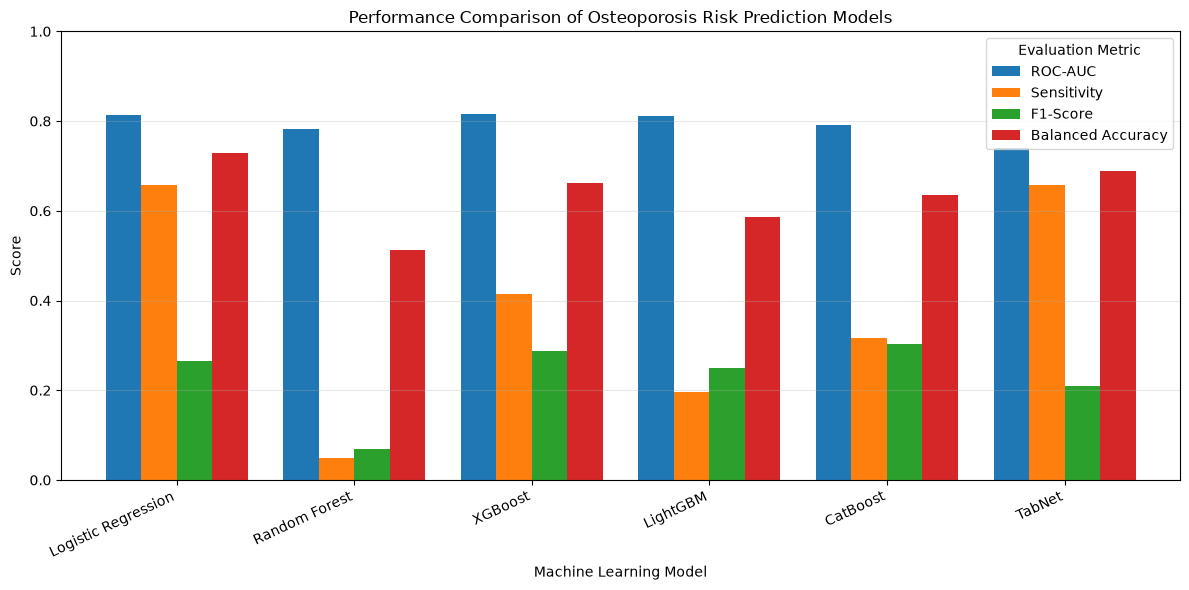

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

models = {
    "Logistic Regression": (lr_prob, lr_pred),
    "Random Forest": (rf_prob, rf_pred),
    "XGBoost": (xgb_prob, xgb_pred),
    "LightGBM": (lgb_prob, lgb_pred),
    "CatBoost": (cat_prob, cat_pred),
    "TabNet": (tab_prob, tab_pred)
}

results = []

for name, (prob, pred) in models.items():
    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Sensitivity": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, pred)
    })

results_df = pd.DataFrame(results).set_index("Model")

print(results_df.round(3))

# Plot
ax = results_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of Osteoporosis Risk Prediction Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

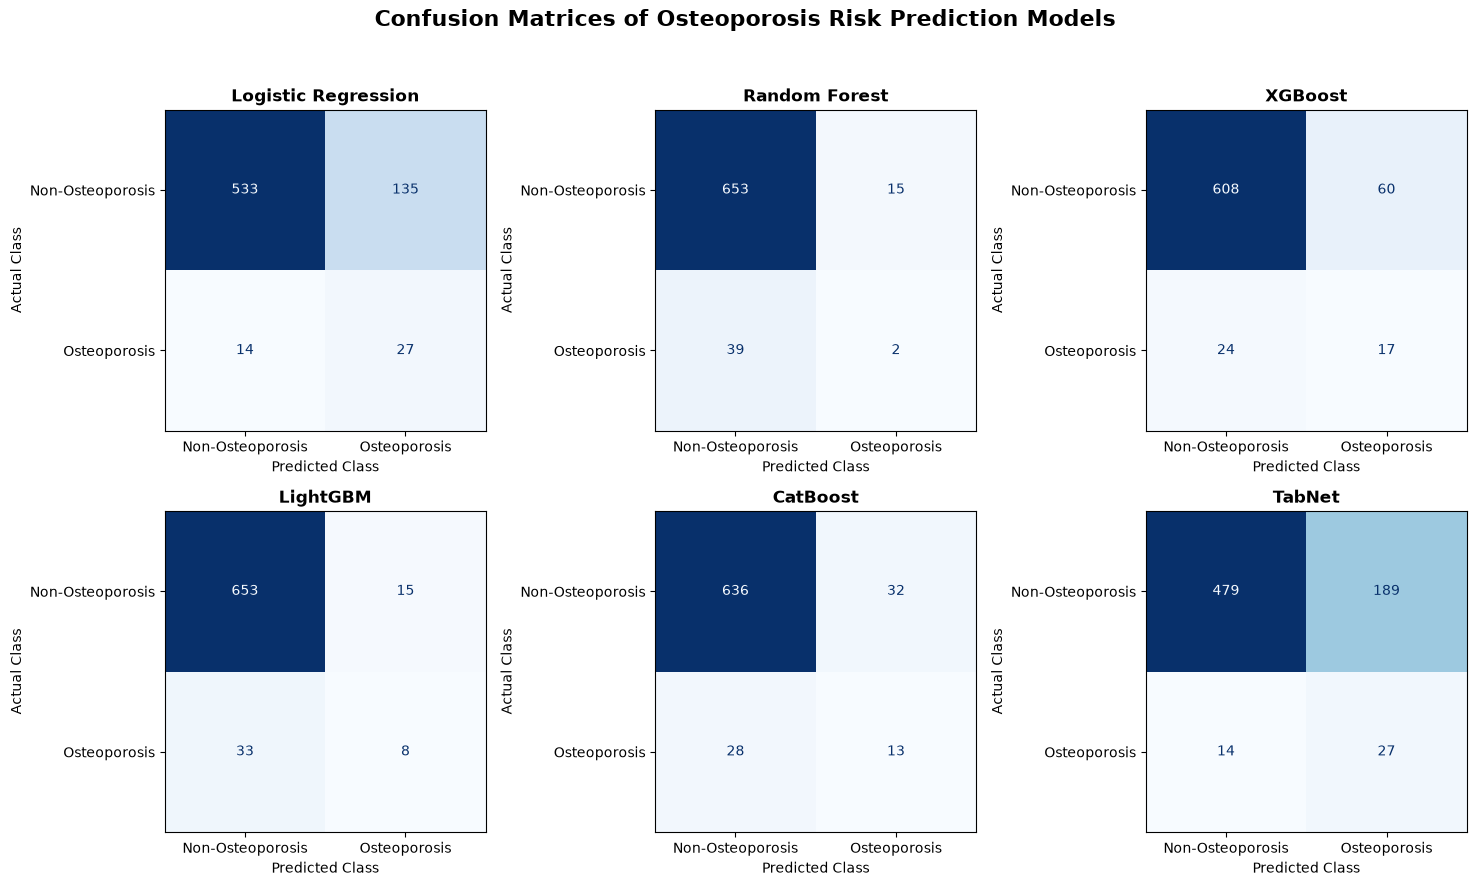

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions from all six models
predictions = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
    "LightGBM": lgb_pred,
    "CatBoost": cat_pred,
    "TabNet": tab_pred
}

# Create 2 x 3 figure
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes = axes.flatten()

for ax, (name, pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-Osteoporosis", "Osteoporosis"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle(
    "Confusion Matrices of Osteoporosis Risk Prediction Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Save high-resolution image for research paper
plt.savefig(
    "confusion_matrices_all_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

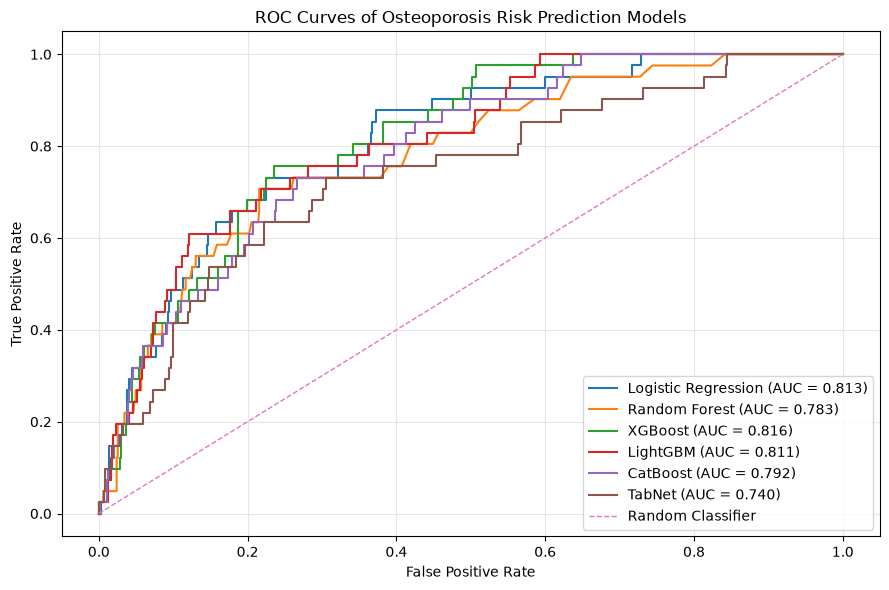

In [34]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Model probabilities
probabilities = {
    "Logistic Regression": lr_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob,
    "LightGBM": lgb_prob,
    "CatBoost": cat_prob,
    "TabNet": tab_prob
}

plt.figure(figsize=(9, 6))

# Plot ROC curve for each model
for name, prob in probabilities.items():
    
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    
    plt.plot(
        fpr,
        tpr,
        linewidth=1.5,
        label=f"{name} (AUC = {auc:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.0,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves of Osteoporosis Risk Prediction Models")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()

# Save high-quality image
plt.savefig(
    "roc_curves_all_models.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

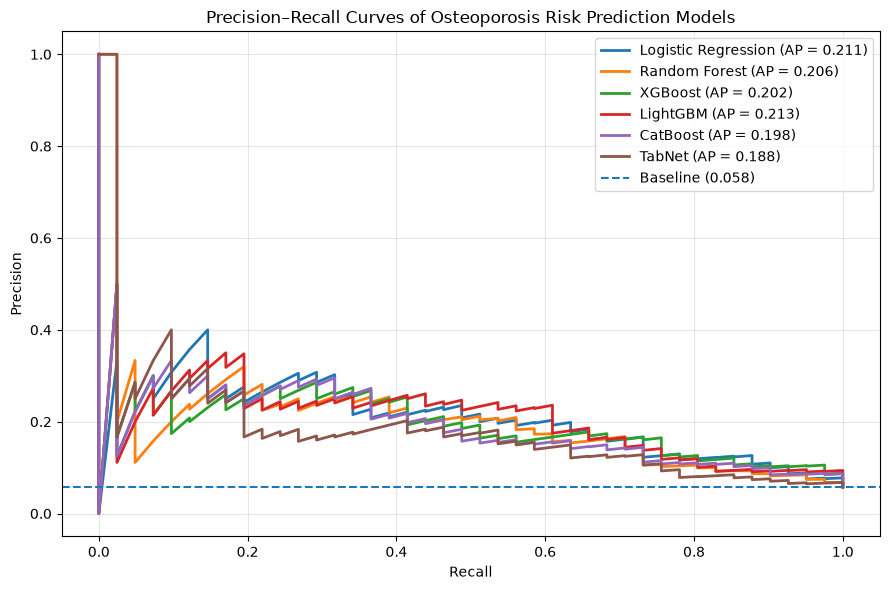

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# Model probabilities
probabilities = {
    "Logistic Regression": lr_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob,
    "LightGBM": lgb_prob,
    "CatBoost": cat_prob,
    "TabNet": tab_prob
}

plt.figure(figsize=(9, 6))

# Plot Precision-Recall curve for each model
for name, prob in probabilities.items():
    
    precision, recall, _ = precision_recall_curve(y_test, prob)
    pr_auc = average_precision_score(y_test, prob)
    
    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP = {pr_auc:.3f})"
    )

# Baseline = proportion of positive samples
baseline = sum(y_test) / len(y_test)

plt.axhline(
    y=baseline,
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline ({baseline:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves of Osteoporosis Risk Prediction Models")

plt.legend(loc="upper right")
plt.grid(alpha=0.3)

plt.tight_layout()

# Save image
plt.savefig(
    "precision_recall_curves_all_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


Calculating Logistic Regression SHAP...
Calculating Random Forest SHAP...
Calculating XGBoost SHAP...
Calculating LightGBM SHAP...


C:\Users\prasa\anaconda3\Lib\site-packages\shap\explainers\_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Calculating CatBoost SHAP...


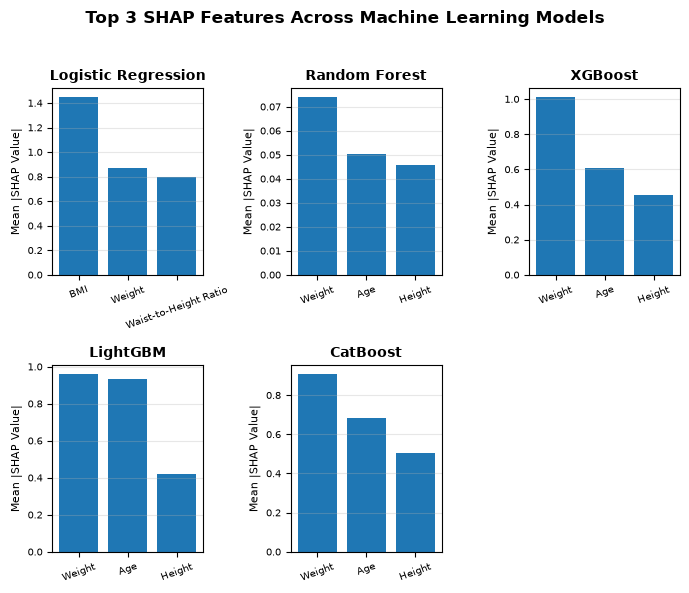

In [17]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Readable feature-name function
# ---------------------------------------------------------

name_map = {
    "RIDAGEYR": "Age",
    "INDFMPIR": "Income-to-Poverty Ratio",
    "BMXWT": "Weight",
    "BMXHT": "Height",
    "BMXBMI": "BMI",
    "BMXWAIST": "Waist Circumference",
    "BMXHIP": "Hip Circumference",
    "PAD680": "Sedentary Time",
    "DR1TKCAL": "Energy Intake",
    "DR1TPROT": "Protein Intake",
    "DR1TVD": "Vitamin D Intake",
    "DR1TCALC": "Calcium Intake",
    "DR1TPHOS": "Phosphorus Intake",
    "DR1TMAGN": "Magnesium Intake",

    "RIAGENDR_1": "Male",
    "RIAGENDR_2": "Female",

    "RIDRETH3_1": "Mexican American",
    "RIDRETH3_2": "Other Hispanic",
    "RIDRETH3_3": "Non-Hispanic White",
    "RIDRETH3_4": "Non-Hispanic Black",
    "RIDRETH3_6": "Non-Hispanic Asian",
    "RIDRETH3_7": "Other / Multiracial",

    "Alcohol_Ever": "Alcohol Use",
    "MCQ080": "Overweight History",
    "MCQ160A": "Arthritis",
    "MCQ160M": "Thyroid Condition",
    "MCQ160L": "Liver Condition",
    "MCQ160P": "Emphysema / COPD",
    "MCQ220": "Cancer History",

    "Waist_Height_Ratio": "Waist-to-Height Ratio",
    "Waist_Hip_Ratio": "Waist-to-Hip Ratio",
    "Age_BMI": "Age × BMI",
    "Calcium_per_1000kcal": "Calcium per 1000 kcal",
    "VitaminD_per_1000kcal": "Vitamin D per 1000 kcal",
    "Protein_per_kg": "Protein per kg",
    "Physical_Activity_Score": "Physical Activity Score"
}


def readable_names(feature_names):

    final_names = []

    for name in feature_names:

        # Remove sklearn prefixes
        clean = str(name)

        clean = clean.replace("num__", "")
        clean = clean.replace("cat__", "")
        clean = clean.replace("remainder__", "")

        # Convert technical code to readable name
        clean = name_map.get(clean, clean)

        final_names.append(clean)

    return final_names


# ---------------------------------------------------------
# Function to calculate SHAP importance
# ---------------------------------------------------------

def get_shap_importance(pipeline, X, model_type):

    preprocessor = pipeline.named_steps["preprocessor"]

    # Get final estimator automatically
    estimator = list(pipeline.named_steps.values())[-1]

    X_transformed = preprocessor.transform(X)

    if hasattr(X_transformed, "toarray"):
        X_transformed = X_transformed.toarray()

    X_transformed = np.asarray(X_transformed)

    feature_names = readable_names(
        preprocessor.get_feature_names_out()
    )

    # Use a sample to reduce SHAP computation time
    if len(X_transformed) > 300:
        X_shap = X_transformed[:300]
    else:
        X_shap = X_transformed

    if model_type == "linear":

        explainer = shap.LinearExplainer(
            estimator,
            X_shap
        )

        shap_values = explainer.shap_values(X_shap)

    else:

        explainer = shap.TreeExplainer(estimator)

        shap_values = explainer.shap_values(X_shap)

    # Handle different SHAP output formats
    if isinstance(shap_values, list):
        shap_values = shap_values[-1]

    shap_values = np.asarray(shap_values)

    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, -1]

    importance = np.abs(shap_values).mean(axis=0)

    result = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    })

    result = result.sort_values(
        "Importance",
        ascending=False
    ).head(10)

    return result


# ---------------------------------------------------------
# Logistic Regression
# ---------------------------------------------------------

print("Calculating Logistic Regression SHAP...")

lr_shap = get_shap_importance(
    log_model,
    X_test,
    "linear"
)


# ---------------------------------------------------------
# Random Forest
# ---------------------------------------------------------

print("Calculating Random Forest SHAP...")

rf_shap = get_shap_importance(
    rf_model,
    X_test,
    "tree"
)


# ---------------------------------------------------------
# XGBoost
# ---------------------------------------------------------

print("Calculating XGBoost SHAP...")

xgb_shap = get_shap_importance(
    xgb_model,
    X_test,
    "tree"
)


# ---------------------------------------------------------
# LightGBM
# ---------------------------------------------------------

print("Calculating LightGBM SHAP...")

lgb_shap = get_shap_importance(
    lgb_model,
    X_test,
    "tree"
)


# ---------------------------------------------------------
# CatBoost - handled separately because preprocessing
# is stored separately
# ---------------------------------------------------------

print("Calculating CatBoost SHAP...")

X_cat = cat_preprocessor.transform(X_test)

if hasattr(X_cat, "toarray"):
    X_cat = X_cat.toarray()

X_cat = np.asarray(X_cat)

cat_feature_names = readable_names(
    cat_preprocessor.get_feature_names_out()
)

# Use first 300 samples
X_cat_shap = X_cat[:300]

cat_explainer = shap.TreeExplainer(cat_model)

cat_values = cat_explainer.shap_values(X_cat_shap)

if isinstance(cat_values, list):
    cat_values = cat_values[-1]

cat_values = np.asarray(cat_values)

if cat_values.ndim == 3:
    cat_values = cat_values[:, :, -1]

cat_importance = np.abs(cat_values).mean(axis=0)

cat_shap = pd.DataFrame({
    "Feature": cat_feature_names,
    "Importance": cat_importance
})

cat_shap = cat_shap.sort_values(
    "Importance",
    ascending=False
).head(10)

# ---------------------------------------------------------
# Combine SHAP results with model names
# ---------------------------------------------------------

shap_results = {
    "Logistic Regression": lr_shap,
    "Random Forest": rf_shap,
    "XGBoost": xgb_shap,
    "LightGBM": lgb_shap,
    "CatBoost": cat_shap
}
#import matplotlib.pyplot as plt

# Compact figure - Top 3 SHAP features with vertical bars
fig, axes = plt.subplots(
    2, 3,
    figsize=(7, 6)
)

axes = axes.flatten()

for ax, (model_name, df) in zip(axes, shap_results.items()):

    # Select Top 3 features
    top3 = (
        df.sort_values("Importance", ascending=False)
          .head(3)
    )

    # Vertical bar chart
    ax.bar(
        top3["Feature"],
        top3["Importance"]
    )

    ax.set_title(
        model_name,
        fontsize=10,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Mean |SHAP Value|",
        fontsize=8
    )

    ax.set_xlabel("")

    # Rotate feature names slightly
    ax.tick_params(
        axis="x",
        labelrotation=20,
        labelsize=7
    )

    ax.tick_params(
        axis="y",
        labelsize=7
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

# Remove empty sixth subplot
fig.delaxes(axes[5])

plt.suptitle(
    "Top 3 SHAP Features Across Machine Learning Models",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    "shap_top3_five_models_vertical.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Transformed shape: (709, 41)
Explain matrix shape: (709, 41)
Number of features: 41
Number of importance values: 41

Top 3 TabNet Features:
      Feature  Importance
0         Age    1.951886
3      Height    1.466210
16  Age × BMI    1.072933


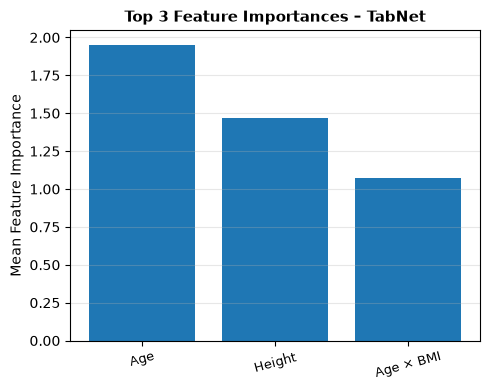

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------------------------------
# Transform test data using TabNet preprocessor
# -------------------------------------------------

X_tab = tabnet_preprocessor.transform(X_test)

if hasattr(X_tab, "toarray"):
    X_tab = X_tab.toarray()

X_tab = np.asarray(X_tab, dtype=np.float32)

print("Transformed shape:", X_tab.shape)


# -------------------------------------------------
# Get TabNet explanations
# -------------------------------------------------

explain_matrix, masks = final_tabnet.explain(X_tab)

print("Explain matrix shape:", explain_matrix.shape)


# -------------------------------------------------
# Calculate global feature importance
# -------------------------------------------------

tabnet_importance = np.mean(
    np.abs(explain_matrix),
    axis=0
)


# -------------------------------------------------
# Get feature names
# -------------------------------------------------

feature_names = tabnet_preprocessor.get_feature_names_out()


# -------------------------------------------------
# Convert technical names to readable names
# -------------------------------------------------

name_map = {
    "RIDAGEYR": "Age",
    "INDFMPIR": "Income-to-Poverty Ratio",

    "BMXWT": "Weight",
    "BMXHT": "Height",
    "BMXBMI": "BMI",
    "BMXWAIST": "Waist Circumference",
    "BMXHIP": "Hip Circumference",

    "PAD680": "Sedentary Time",

    "DR1TKCAL": "Energy Intake",
    "DR1TPROT": "Protein Intake",
    "DR1TVD": "Vitamin D Intake",
    "DR1TCALC": "Calcium Intake",
    "DR1TPHOS": "Phosphorus Intake",
    "DR1TMAGN": "Magnesium Intake",

    "RIAGENDR_1": "Male",
    "RIAGENDR_2": "Female",

    "RIDRETH3_1": "Mexican American",
    "RIDRETH3_2": "Other Hispanic",
    "RIDRETH3_3": "Non-Hispanic White",
    "RIDRETH3_4": "Non-Hispanic Black",
    "RIDRETH3_6": "Non-Hispanic Asian",
    "RIDRETH3_7": "Other / Multiracial",

    "Alcohol_Ever": "Alcohol Use",
    "MCQ080": "Overweight History",
    "MCQ160A": "Arthritis",
    "MCQ160M": "Thyroid Condition",
    "MCQ160L": "Liver Condition",
    "MCQ160P": "Emphysema / COPD",
    "MCQ220": "Cancer History",

    "Waist_Height_Ratio": "Waist-to-Height Ratio",
    "Waist_Hip_Ratio": "Waist-to-Hip Ratio",
    "Age_BMI": "Age × BMI",
    "Calcium_per_1000kcal": "Calcium per 1000 kcal",
    "VitaminD_per_1000kcal": "Vitamin D per 1000 kcal",
    "Protein_per_kg": "Protein per kg",
    "Physical_Activity_Score": "Physical Activity Score"
}


clean_names = []

for name in feature_names:

    clean = str(name)

    clean = clean.replace("num__", "")
    clean = clean.replace("cat__", "")
    clean = clean.replace("remainder__", "")

    clean = name_map.get(clean, clean)

    clean_names.append(clean)


# -------------------------------------------------
# Check dimensions
# -------------------------------------------------

print("Number of features:", len(clean_names))
print("Number of importance values:", len(tabnet_importance))


# -------------------------------------------------
# Create importance table
# -------------------------------------------------

tabnet_df = pd.DataFrame({
    "Feature": clean_names,
    "Importance": tabnet_importance
})

top3_tabnet = (
    tabnet_df
    .sort_values("Importance", ascending=False)
    .head(3)
)

print("\nTop 3 TabNet Features:")
print(top3_tabnet)


# -------------------------------------------------
# Vertical bar chart
# -------------------------------------------------

plt.figure(figsize=(5, 4))

plt.bar(
    top3_tabnet["Feature"],
    top3_tabnet["Importance"]
)

plt.title(
    "Top 3 Feature Importances – TabNet",
    fontsize=11,
    fontweight="bold"
)

plt.ylabel("Mean Feature Importance")

plt.xticks(
    rotation=15,
    fontsize=9
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "tabnet_top3_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()